# Fleet Based Supply

## Run this example in [Colab](https://colab.research.google.com/github/SignalOceanSdk/SignalSDK/blob/master/docs/examples/jupyter/SupplyAPI/FleetBasedSupply.ipynb)

How many Aframax tankers of three commercial operators were in the market each day, with commercial data updated in the last 7 days?

## Setup
Install the Signal Ocean SDK:
```
pip install signal-ocean
```
You need your own API key with access to the Supply API, for the vessel classes that you query. Get your key here: https://apis.signalocean.com/profile

In [ ]:
!pip install signal-ocean

In [2]:
signal_ocean_api_key = ''  # Replace with your subscription key

In [3]:
from datetime import date

import pandas as pd

from signal_ocean import Connection
from signal_ocean.supply import (
    CommercialAvailabilityFilter,
    FromToRange,
    IncludeExcludeFilter,
    SupplyAPI,
    SupplyFilter,
    VesselClass,
    VesselParticularsFilter,
)

connection = Connection(signal_ocean_api_key)
api = SupplyAPI(connection)

## Filters
`commercial_operator` takes company ids. You can find company ids with the Companies API.

In [4]:
operator_ids = [2121, 1684, 6538]

def fleet_filter(operators):
    return SupplyFilter(
        vessel_class=VesselClass.AFRAMAX,
        commercial_availability=CommercialAvailabilityFilter(
            latest_updated_date_relative_offset=FromToRange(from_=-7, to=0)
        ),
        vessel_particulars=VesselParticularsFilter(
            commercial_operator=IncludeExcludeFilter(values=operators)
        ),
    )

## Supply trend of the three fleets together

In [5]:
trend_frame = api.get_supply_trend(date(2026, 8, 1), date(2026, 10, 31), filters=fleet_filter(operator_ids)).to_data_frame()
trend_frame.tail()

,supply
date,
2026-10-27,17
2026-10-28,17
2026-10-29,17
2026-10-30,17
2026-10-31,17


## One trend per operator
One trend call per operator gives a breakdown.

<Axes: title={'center': 'Aframax tankers per operator'}, ylabel='Vessels'>

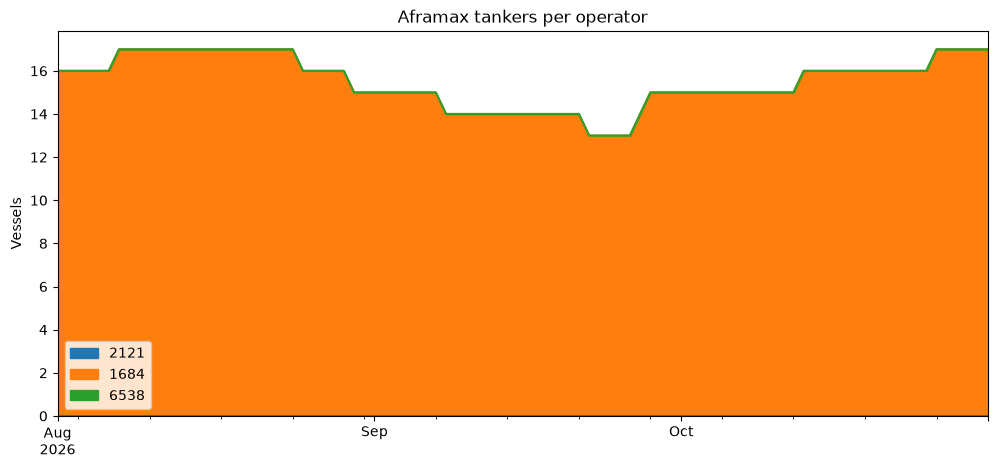

In [6]:
per_operator = pd.concat(
    {
        str(operator): api.get_supply_trend(
            date(2026, 8, 1), date(2026, 10, 31), filters=fleet_filter([operator])
        ).to_data_frame()["supply"]
        for operator in operator_ids
    },
    axis=1,
)
per_operator.plot.area(figsize=(12, 5), title="Aframax tankers per operator",
                       ylabel="Vessels", xlabel="")

## The vessels now

In [7]:
live_frame = api.get_live_supply(filters=fleet_filter(operator_ids)).to_data_frame()
live_frame[["imo", "open_location", "open_date_to", "availability_state", "voyage_state", "ais_current_area"]]

,imo,open_location,open_date_to,availability_state,voyage_state,ais_current_area
0,9997983,Fawley,2026-11-25 10:48:38.559+00:00,Available,Laden,US Atlantic Coast
1,1014101,Pakistan / West Coast India,2026-11-27 16:41:30.342+00:00,Available,Laden,East Mediterranean
2,9979993,Rotterdam,2026-11-19 15:09:41.842+00:00,Available,Laden,West Mediterranean
3,9857468,Donges,2026-11-17 11:26:47.891+00:00,Available,Laden,West Mediterranean
4,9759800,Caribs,2026-11-11 09:05:52.000+00:00,PotentiallyFixed,BallastUnfixed,US Atlantic Coast
5,1014096,Le Havre,2026-11-21 02:28:46.671+00:00,Available,Laden,Canada Atlantic Coast
6,9473066,Trieste,2026-11-16 00:00:00.000+00:00,Available,Laden,Central Mediterranean
7,9407457,Mediterranean,2026-11-18 23:08:33.893+00:00,OnSubs,BallastFixed,East Mediterranean
8,9997957,US Atlantic Coast,2026-11-11 09:06:33.000+00:00,OnSubs,BallastUnfixed,US Atlantic Coast
9,9843209,Pakistan / West Coast India,2026-12-03 04:03:08.650+00:00,Available,Laden,Iberian Atlantic Coast


In [8]:
connection.close()